# June 500mb Geopotential Height EOF Analysis — Minnesota Lake VHT
Ch 2 Paper Aug/Sep 2026

Files produced: EOF_scores.csv


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import time
from scipy import signal
from scipy.stats import pearsonr, linregress
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.ticker import MaxNLocator
import cartopy.crs as ccrs
import cartopy.feature as cfeature


## 2. Load geopotential data and convert to geopotential height (m)

ERA5 `z` is **geopotential** (m² s⁻²), not geopotential height. Divide by
g = 9.80665 m/s² to get height in meters (standard conversion).

Also checks the `expver` coordinate for mixed ERA5 / ERA5T experiment versions,
which can introduce NaNs at overlapping/transition time steps if not handled.


In [2]:
G = 9.80665  # m/s^2, standard gravity

dr = xr.open_dataset("c5ba46cd43b3e536dc0079d52b793149.nc")
print(dr)

geopotential = dr.z  # units: m**2 s**-2

# drop the singleton pressure_level dimension (already 500mb only)
geopotential = geopotential.squeeze('pressure_level', drop=True)

# convert geopotential -> geopotential height (meters)
geoheight = geopotential / G
geoheight.attrs['units'] = 'm'
geoheight.attrs['long_name'] = 'Geopotential height'

print(f"\nConverted to geopotential height. Range: "
      f"{float(geoheight.min()):.1f} to {float(geoheight.max()):.1f} m")


<xarray.Dataset> Size: 125MB
Dimensions:         (valid_time: 205, pressure_level: 1, latitude: 181,
                     longitude: 281)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * pressure_level  (pressure_level) float64 8B 500.0
  * latitude        (latitude) float64 1kB 70.0 69.75 69.5 ... 25.5 25.25 25.0
  * longitude       (longitude) float64 2kB -130.0 -129.8 ... -60.25 -60.0
    number          int64 8B ...
    expver          (valid_time) <U4 3kB ...
Data variables:
    z               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
    u               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution

In [3]:
# check for mixed expver (ERA5 vs ERA5T) causing possible NaNs ──────
if 'expver' in dr.coords:
    unique_expver = np.unique(dr['expver'].values)
    print(f"Unique expver values found: {unique_expver}")
    if len(unique_expver) > 1:
        print("WARNING: multiple expver values present — this can indicate a mix of "
              "final ERA5 and near-real-time ERA5T data. Check for NaNs introduced "
              "at the transition below.")

n_nan_raw = int(np.isnan(geoheight.values).sum())
print(f"\nNaN count in raw geoheight: {n_nan_raw} of {geoheight.size} total values")


Unique expver values found: ['0001']

NaN count in raw geoheight: 0 of 10426505 total values


## 3. Domain subset (40–70°N, 130–70°W)


In [4]:
geoheight_domain = geoheight.sel(
    latitude=slice(70, 40),      # ERA5 latitude is typically stored descending (90 -> -90)
    longitude=slice(-130, -70)
)
              
print(f"Domain subset shape: {geoheight_domain.shape}")
print(f"Latitude range: {geoheight_domain.latitude.min().item()} to {geoheight_domain.latitude.max().item()}")
print(f"Longitude range: {geoheight_domain.longitude.min().item()} to {geoheight_domain.longitude.max().item()}")


Domain subset shape: (205, 121, 241)
Latitude range: 40.0 to 70.0
Longitude range: -130.0 to -70.0


## 4. Remove monthly climatology (deseasonalize)

Standard EOF prep: compute the mean for each calendar month across the record,
then subtract that month's mean from every time step in that month.


In [5]:
climo = geoheight_domain.groupby('valid_time.month').mean('valid_time')
norm_geoheight = geoheight_domain.groupby('valid_time.month') - climo


## 5. Isolate June

In [6]:
june_hgt = norm_geoheight.sel(valid_time=norm_geoheight.valid_time.dt.month == 6)
print(f"June time steps: {june_hgt.sizes['valid_time']}")


June time steps: 41


## 6. Coarsen spatial resolution (0.25° → 1.0°)

`coarsen(latitude=4, longitude=4)` averages blocks of 4x4 grid cells on a 0.25° grid,
producing 1.0° resolution


In [7]:
june_hgt_coarse = june_hgt.coarsen(latitude=4, longitude=4, boundary='trim').mean()
print(f"Original shape: {june_hgt.shape}")
print(f"Coarsened shape: {june_hgt_coarse.shape}")


Original shape: (41, 121, 241)
Coarsened shape: (41, 30, 60)


## 7. Load lake VHT data and find common years

In [8]:
lake_df = pd.read_csv('lake_VHT.csv')
lake_pivot = lake_df.pivot(index='year', columns='lagoslakeid', values='VHT')

common_years = np.intersect1d(
    june_hgt_coarse.valid_time.dt.year.values,
    lake_pivot.index.values
)

common_years = common_years[(common_years >= 1980) & (common_years <= 2020)]

june_hgt_common = june_hgt_coarse.sel(
    valid_time=june_hgt_coarse.valid_time.dt.year.isin(common_years)
)
lake_pivot_common = lake_pivot.loc[common_years]

vht_index = lake_pivot_common.mean(axis=1).values  

n_years = len(common_years)
n_lat   = len(june_hgt_common.latitude)
n_lon   = len(june_hgt_common.longitude)
lats    = june_hgt_common.latitude.values
lons    = june_hgt_common.longitude.values
hgt_reshaped = june_hgt_common.values.reshape(n_years, -1)

years_all = common_years

print(f"Common years: {common_years.min()}–{common_years.max()}, n={n_years}")
print(f"Grid: {n_lat} lat x {n_lon} lon")


Common years: 1980–2020, n=41
Grid: 30 lat x 60 lon


## 8. Build spatially-selected lake index + reliable-years mask



In [9]:
lake_completeness = lake_pivot_common.notna().sum().sort_values(ascending=False)
lake_coords = lake_df.drop_duplicates(subset='lagoslakeid')[
    ['lagoslakeid', 'latitude', 'longitude']
].set_index('lagoslakeid')
lake_info = pd.DataFrame({'n_years': lake_completeness}).join(lake_coords)

lat_bins = np.arange(43.5, 50.0, 1.0)
lon_bins = np.arange(-97.5, -89.5, 2.0)
lake_info['lat_bin'] = pd.cut(lake_info['latitude'],  bins=lat_bins, labels=False)
lake_info['lon_bin'] = pd.cut(lake_info['longitude'], bins=lon_bins, labels=False)
lake_info['cell']    = lake_info['lat_bin'].astype(str) + '_' + lake_info['lon_bin'].astype(str)

min_years      = 7
lakes_per_cell = 2
spatially_selected = (
    lake_info[lake_info['n_years'] >= min_years]
    .sort_values('n_years', ascending=False)
    .groupby('cell')
    .head(lakes_per_cell)
    .reset_index()
)
print(f"Selected {len(spatially_selected)} lakes across {spatially_selected['cell'].nunique()} grid cells")

selected_ids = spatially_selected['lagoslakeid'].values
lake_pivot_spatial = lake_pivot_common[
    [l for l in selected_ids if l in lake_pivot_common.columns]
]
lake_index_spatial = np.nanmean(lake_pivot_spatial.values, axis=1)

lakes_per_year  = lake_pivot_spatial.notna().sum(axis=1)
reliable_years  = lakes_per_year[lakes_per_year >= 10].index.values
reliable_mask   = np.isin(common_years, reliable_years)
lake_index_rel   = lake_index_spatial[reliable_mask]
common_years_rel = common_years[reliable_mask]

print(f"Reliable period: {reliable_years.min()}–{reliable_years.max()}, n={len(reliable_years)} years")


Selected 22 lakes across 13 grid cells
Reliable period: 1994–2020, n=17 years


## 9. Detrend at each grid point

DelSole & Tippett (2021): remove the temporal mean (already done via monthly
climatology) **and** the linear trend at each grid point, to reduce the influence
of long-term climate change on the leading EOF modes


In [10]:
n_nan = np.isnan(hgt_reshaped).sum()
print(f"NaN count in hgt_reshaped: {n_nan} of {hgt_reshaped.size} total values")

t = np.arange(hgt_reshaped.shape[0])  # 0..40, linear trend is scale-invariant to actual year values

if n_nan == 0:
    print("No NaNs found — using scipy.signal.detrend (vectorized).")
    hgt_detrended = signal.detrend(hgt_reshaped, axis=0, type='linear')
else:
    print("NaNs found — using per-gridpoint linregress (NaN-safe).")
    hgt_detrended = np.full_like(hgt_reshaped, np.nan)
    n_cols = hgt_reshaped.shape[1]
    for col in range(n_cols):
        col_vals = hgt_reshaped[:, col]
        valid = ~np.isnan(col_vals)
        if valid.sum() < 2:
            continue
        slope, intercept, r, p, se = linregress(t[valid], col_vals[valid])
        trend = slope * t + intercept
        hgt_detrended[valid, col] = col_vals[valid] - trend[valid]

print(f"Detrended shape: {hgt_detrended.shape}")
hgt_reshaped = hgt_detrended  # replace with detrended version for everything downstream


NaN count in hgt_reshaped: 0 of 73800 total values
No NaNs found — using scipy.signal.detrend (vectorized).
Detrended shape: (41, 1800)


## 10. Latitude weighting + PCA

Weight each grid point by sqrt(cos(latitude)) to account for meridian convergence
at higher latitudes, then fit PCA on the weighted, detrended anomaly field
(all 41 years, 1980–2020).


In [11]:
lat_weights_1d = np.sqrt(np.cos(np.deg2rad(lats)))   # (n_lat,)
weights = np.repeat(lat_weights_1d, n_lon)            # (n_lat*n_lon,)

hgt_weighted = hgt_reshaped * weights[None, :]

valid_cols = ~np.isnan(hgt_weighted).any(axis=0)
print(f"Valid grid columns for PCA: {valid_cols.sum()} of {n_lat*n_lon}")

hgt_for_pca = hgt_weighted[:, valid_cols]

n_components = 3
pca = PCA(n_components=n_components)
pcs_all = pca.fit_transform(hgt_for_pca)

n_y, n_x = n_lat, n_lon

print(f"\nExplained variance ratio: {pca.explained_variance_ratio_[:3]}")
print(f"PCA fit on {hgt_for_pca.shape[0]} years, {hgt_for_pca.shape[1]} valid grid points")


Valid grid columns for PCA: 1800 of 1800

Explained variance ratio: [0.36032547 0.20341345 0.17581538]
PCA fit on 41 years, 1800 valid grid points


## 11. Validate PC1, PC2, PC3 against the lake index (reliable years only)

In [12]:
print("PC score ranges:")
print(f"  PC1: {pcs_all[:,0].min():.1f} to {pcs_all[:,0].max():.1f}")
print(f"  PC2: {pcs_all[:,1].min():.1f} to {pcs_all[:,1].max():.1f}")
print(f"  PC3: {pcs_all[:,2].min():.1f} to {pcs_all[:,2].max():.1f}")

for i, pc_name in enumerate(['PC1', 'PC2', 'PC3']):
    pc_all   = pcs_all[:, i]
    pc_rel   = pc_all[reliable_mask]
    valid_pc = np.isfinite(lake_index_rel)
    r_pc, p_pc = pearsonr(pc_rel[valid_pc], lake_index_rel[valid_pc])
    print(f"\n{pc_name} vs lake index: r = {r_pc:.3f}, p = {p_pc:.4f}")


PC score ranges:
  PC1: -1214.4 to 1645.0
  PC2: -972.6 to 1608.4
  PC3: -1033.7 to 690.2

PC1 vs lake index: r = -0.537, p = 0.0262

PC2 vs lake index: r = -0.183, p = 0.4813

PC3 vs lake index: r = -0.165, p = 0.5270


## 12. Standardize PCs and save to CSV

In [13]:
def standardize(x):
    return (x - np.mean(x)) / np.std(x)

eof_df = pd.DataFrame({
    "year" : years_all,
    "PC1"  : standardize(pcs_all[:, 0]),
    "PC2"  : standardize(pcs_all[:, 1]),
    "PC3"  : standardize(pcs_all[:, 2])
})
eof_df.to_csv("EOF_scores.csv", index=False)
print(f"EOF scores saved: {len(eof_df)} years ({years_all.min()}–{years_all.max()})")
print(eof_df)


EOF scores saved: 41 years (1980–2020)
    year       PC1       PC2       PC3
0   1980 -0.016869 -0.464478  0.618698
1   1981 -1.883774  0.376570 -1.104143
2   1982 -0.849166  1.622312  1.477185
3   1983  0.538483  0.646295 -0.626117
4   1984  0.376791  0.405429 -0.779292
5   1985 -0.707184  1.205073  0.901290
6   1986 -1.237743 -2.007983  0.735220
7   1987  0.115353 -1.197894  0.850738
8   1988  2.551736 -1.652735  1.215862
9   1989  0.995030  0.791051  0.835540
10  1990 -0.712198 -0.784136 -0.817016
11  1991  2.240166  0.226291 -0.848101
12  1992 -0.661638  0.258898  1.532832
13  1993 -0.489164  0.443080 -1.121830
14  1994  0.061578 -1.124045 -0.917087
15  1995  2.278444  0.005758  0.040172
16  1996  1.042671 -0.112632 -0.517928
17  1997 -0.038670  0.094068 -0.751924
18  1998  0.731828  3.320735  0.921609
19  1999 -0.066232 -0.032457 -1.834894
20  2000 -1.796771 -0.712820  0.460959
21  2001  0.058686 -0.332361 -0.994832
22  2002  0.002475 -0.887367 -0.019532
23  2003 -1.184916 -0.469

## 13. Regression maps

Regress the **unweighted** detrended height anomaly field onto each standardized PC


In [14]:
def make_regression_map(k):
    pc_std = standardize(pcs_all[:, k])
    reg = (hgt_reshaped.T @ pc_std) / (len(pc_std) - 1)  # meters per sigma PC
    reg_full = np.full(n_y * n_x, np.nan)
    reg_full[valid_cols] = reg[valid_cols]
    return reg_full.reshape(n_y, n_x)

regression_maps = [make_regression_map(k) for k in range(n_components)]

lons_plot = lons
lats_plot = lats


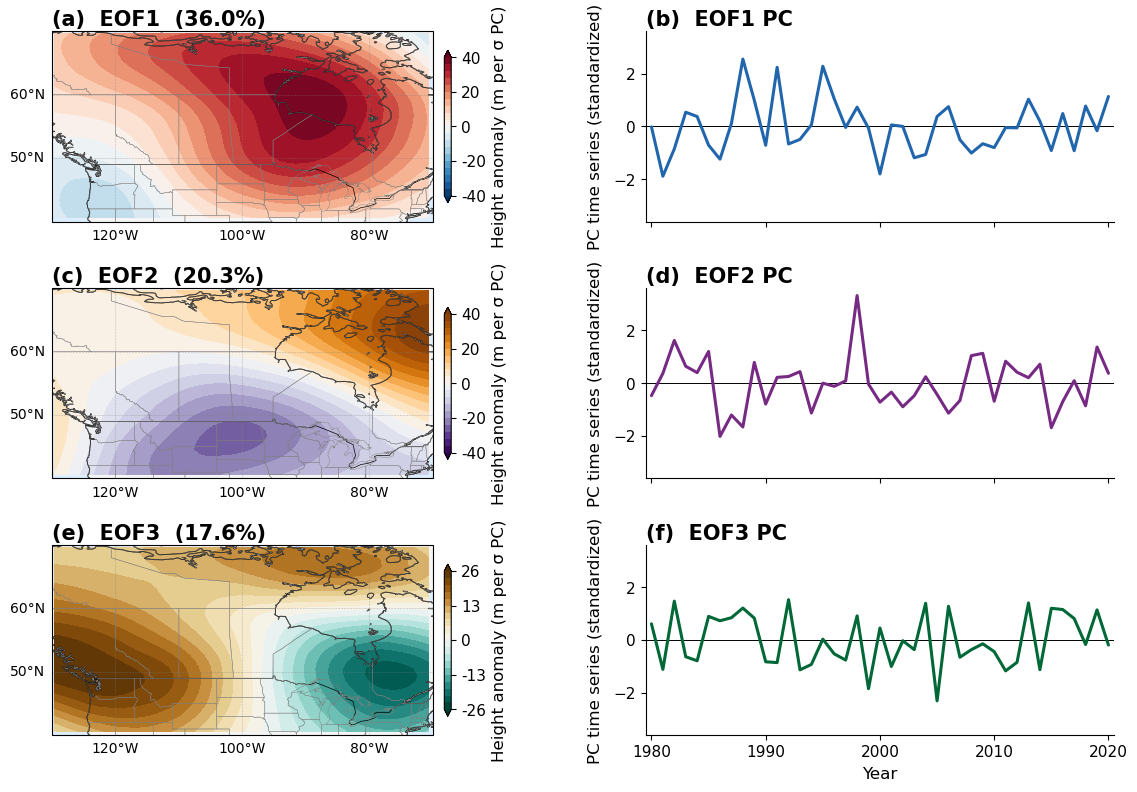

3x2 layout saved.


In [15]:
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

FS_TITLE   = 15
FS_GRID    = 10
FS_CBAR_TK = 11
FS_CBAR_LB = 12
FS_AXLABEL = 12
FS_TICK    = 11


def format_ax(ax):
    ax.set_extent(
        [-130, -70, 40, 70],
        crs=ccrs.PlateCarree())

    ax.coastlines(
        resolution='50m',
        linewidth=0.7)

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.5)

    ax.add_feature(
        cfeature.STATES,
        linewidth=0.3,
        edgecolor='gray')

    ax.add_feature(
        cfeature.LAND,
        facecolor='#f5f5f5',
        zorder=0)

    ax.add_feature(
        cfeature.OCEAN,
        facecolor='#ddeeff',
        zorder=0)


EOF_CMAPS = [
    'RdBu_r',
    'PuOr_r',
    'BrBG_r'
]


PC_COLORS = [
    '#2166ac',   # PC1
    '#762a83',   # PC2
    '#006837',   # PC3
]


fig = plt.figure(
    figsize=(12, 8))

gs = gridspec.GridSpec(
    3, 2,
    figure=fig,
    width_ratios=[1, 1],
    height_ratios=[1, 1, 1],

    # Keep enough horizontal space for the PC y-axis labels
    hspace=0.35,
    wspace=0.28,

    top=0.95,
    bottom=0.07,
    left=0.075,
    right=0.965
)


panel_letters = [
    ['(a)', '(b)'],
    ['(c)', '(d)'],
    ['(e)', '(f)']
]


# Standardized PC limits

all_pc_vals = [
    standardize(pcs_all[:, k])
    for k in range(n_components)
]

ymax = max(
    np.abs(v).max()
    for v in all_pc_vals)

ylim = (
    -round(ymax + 0.3, 1),
     round(ymax + 0.3, 1))

for k in range(3):

    var_pct = (
        pca.explained_variance_ratio_[k] * 100)

    ax_map = fig.add_subplot(
        gs[k, 0],
        projection=ccrs.PlateCarree())

    reg_map = regression_maps[k]
    cmap_k = EOF_CMAPS[k]

    raw_vmax = np.nanmax(
        np.abs(reg_map))

    decimals = (0 if raw_vmax >= 10 else 2)

    scale = 10 ** decimals

    vmax = (np.ceil(raw_vmax * scale) / scale)


    cf = ax_map.contourf(
        lons_plot,
        lats_plot,
        reg_map,
        levels=np.linspace(
            -vmax,
            vmax,
            21
        ),
        cmap=cmap_k,
        extend='both',
        transform=ccrs.PlateCarree()
    )
    
    format_ax(ax_map)
    
    gl = ax_map.gridlines(
        draw_labels=True,
        linewidth=0.4,
        color='gray',
        alpha=0.5,
        linestyle='--'
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlocator = mticker.FixedLocator([-120, -100, -80, -60])
    gl.ylocator = mticker.FixedLocator([30, 40, 50, 60, 70])
    gl.xlabel_style = {'size': FS_GRID}
    gl.ylabel_style = {'size': FS_GRID}
    ax_map.set_title(
        f'{panel_letters[k][0]}  EOF{k+1}  ({var_pct:.1f}%)',
        fontsize=FS_TITLE,
        fontweight='bold',
        loc='left',
        pad=4)

    cbar = plt.colorbar(
        cf,
        ax=ax_map,
        orientation='vertical',
        pad=0.025,
        shrink=0.80,
        aspect=22)


    tick_vals = [-vmax, -vmax / 2, 0, vmax / 2, vmax]

    fmt = (
        '{:.0f}'
        if decimals == 0
        else '{:.2f}'
    )

    cbar.set_ticks(tick_vals)

    cbar.set_ticklabels([
        fmt.format(t)
        for t in tick_vals])

    cbar.set_label(
        'Height anomaly (m per σ PC)',
        fontsize=FS_CBAR_LB)

    cbar.ax.tick_params(
        labelsize=FS_CBAR_TK)

    ax_pc = fig.add_subplot(
        gs[k, 1])

    pc_vals = all_pc_vals[k]
    pc_color = PC_COLORS[k]

    ax_pc.axhline(
        0,
        color='black',
        linewidth=0.7,
        zorder=1)
    
    ax_pc.plot(
        years_all,
        pc_vals,
        color=pc_color,
        linewidth=2.2,
        solid_capstyle='round',
        zorder=2)

    ax_pc.set_xlim(
        years_all.min() - 0.5, years_all.max() + 0.5)
    ax_pc.set_ylim(ylim)

    ax_pc.tick_params(
        axis='both',
        labelsize=FS_TICK)

    ax_pc.yaxis.set_major_locator(
        MaxNLocator(
            nbins=4,
            symmetric=True
        )
    )

    ax_pc.set_xticks([
        1980,
        1990,
        2000,
        2010,
        2020    ])

    ax_pc.spines[['top', 'right']].set_visible(False)

    ax_pc.set_ylabel(
        'PC time series (standardized)',
        fontsize=FS_AXLABEL,
        labelpad=8)
    
    if k == 2:

        ax_pc.set_xlabel(
            'Year',
            fontsize=FS_AXLABEL,
            labelpad=5)
    else:
        ax_pc.set_xticklabels([])

    ax_pc.set_title(
        f'{panel_letters[k][1]}  EOF{k+1} PC',
        fontsize=FS_TITLE,
        fontweight='bold',
        loc='left',
        pad=4)


plt.savefig('eof_3x2_panel.png', dpi=600, bbox_inches='tight')
plt.show()
print("3x2 layout saved.")

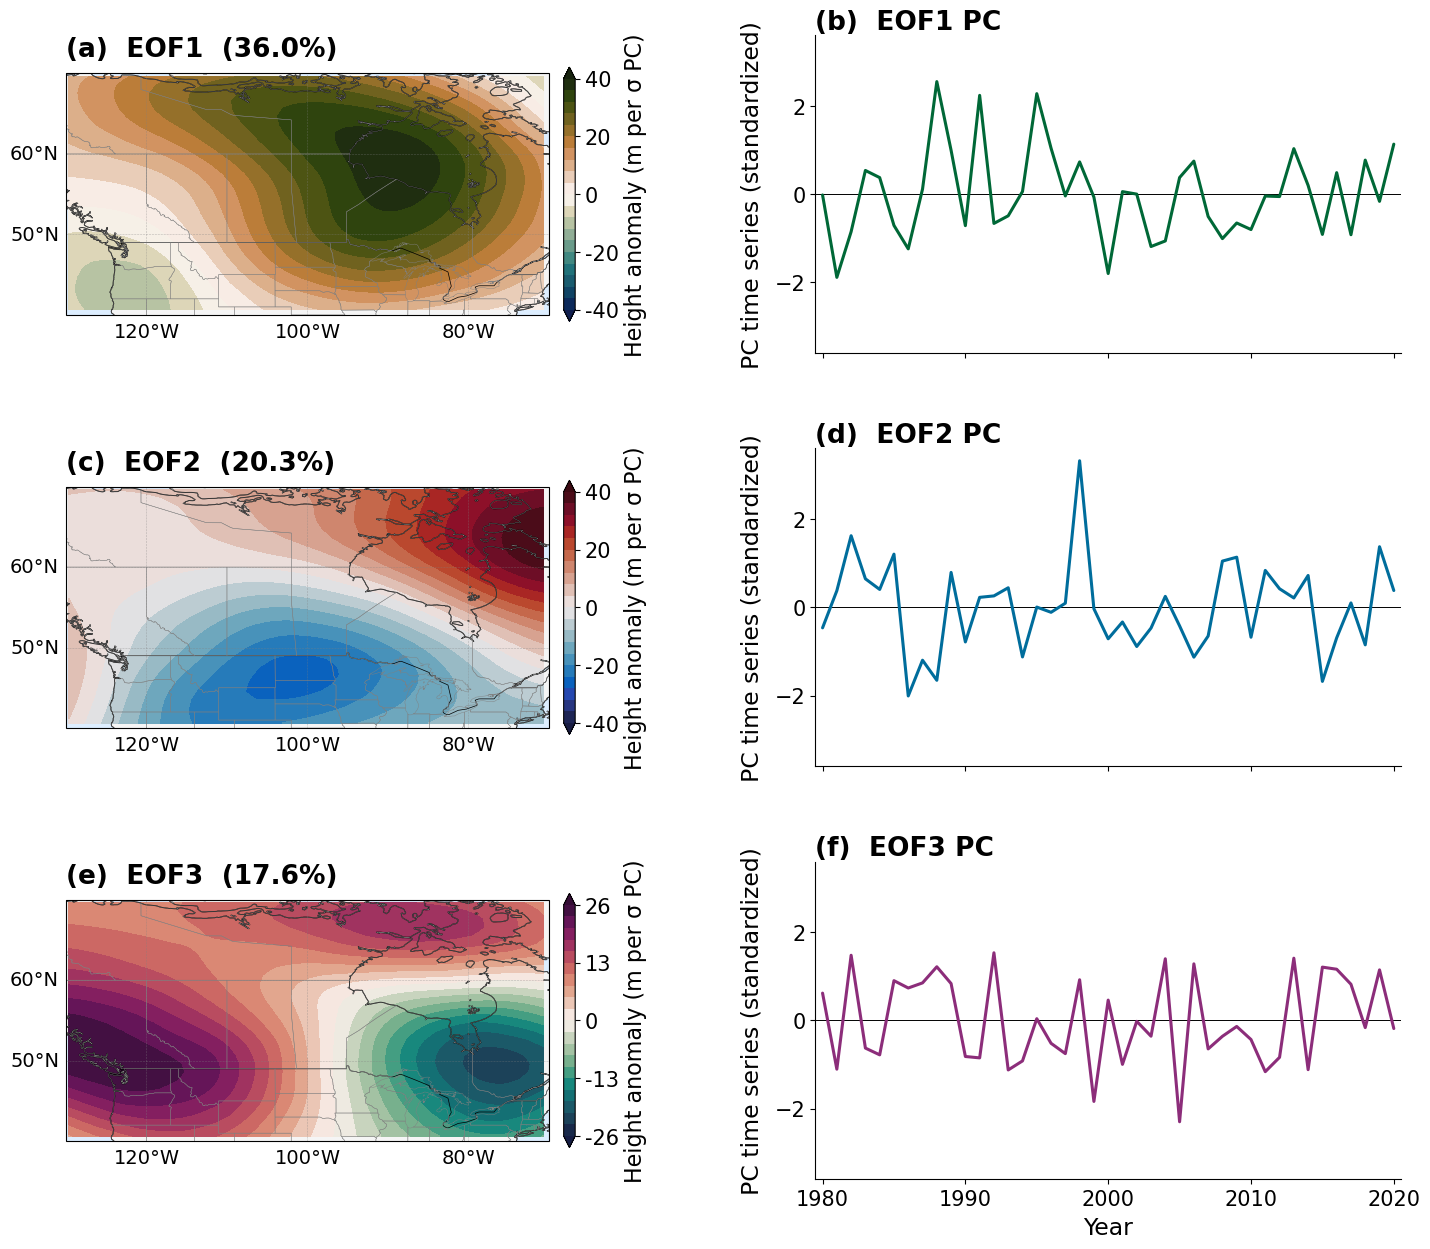

3x2 layout saved.


In [65]:
import cmocean

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 17,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
})

FS_TITLE   = 19
FS_GRID    = 14
FS_CBAR_TK = 15
FS_CBAR_LB = 16
FS_AXLABEL = 17
FS_TICK    = 15

def format_ax(ax):
    ax.set_extent([-130, -70, 40, 70], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='50m', linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='gray')
    ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor='#ddeeff', zorder=0)

EOF_CMAPS = [
    cmocean.cm.tarn_r,
    cmocean.cm.balance,
    cmocean.cm.curl
]

PC_COLORS = [
    '#006837',  # PC3 - dark green
    '#006D9C',  # PC1 - dark blue
    '#8C2D7A',  # PC2 - dark purple
    
]

fig = plt.figure(figsize=(15, 13))

gs = gridspec.GridSpec(
    3, 2,
    figure=fig,
    width_ratios=[1, 1],
    height_ratios=[1, 1, 1],
    hspace=0.30,
    wspace=0.28,
    top=0.95,
    bottom=0.07,
    left=0.075,
    right=0.965
)

panel_letters = [
    ['(a)', '(b)'],
    ['(c)', '(d)'],
    ['(e)', '(f)']
]

all_pc_vals = [standardize(pcs_all[:, k]) for k in range(n_components)]
ymax = max(np.abs(v).max() for v in all_pc_vals)
ylim = (-round(ymax + 0.3, 1), round(ymax + 0.3, 1))

for k in range(3):
    var_pct = pca.explained_variance_ratio_[k] * 100

    # EOF map
    ax_map = fig.add_subplot(gs[k, 0], projection=ccrs.PlateCarree())
    reg_map = regression_maps[k]
    cmap_k = EOF_CMAPS[k]

    raw_vmax = np.nanmax(np.abs(reg_map))
    decimals = 0 if raw_vmax >= 10 else 2
    scale = 10 ** decimals
    vmax = np.ceil(raw_vmax * scale) / scale

    cf = ax_map.contourf(
        lons_plot,
        lats_plot,
        reg_map,
        levels=np.linspace(-vmax, vmax, 21),
        cmap=cmap_k,
        extend='both',
        transform=ccrs.PlateCarree()
    )

    format_ax(ax_map)

    gl = ax_map.gridlines(
        draw_labels=True,
        linewidth=0.4,
        color='gray',
        alpha=0.5,
        linestyle='--'
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([-120, -100, -80, -60])
    gl.ylocator = mticker.FixedLocator([30, 40, 50, 60, 70])
    gl.xlabel_style = {'size': FS_GRID}
    gl.ylabel_style = {'size': FS_GRID}

    ax_map.set_title(
        f'{panel_letters[k][0]}  EOF{k+1}  ({var_pct:.1f}%)',
        fontsize=FS_TITLE,
        fontweight='bold',
        loc='left',
        pad=12
    )

    # Colorbar
    cbar = plt.colorbar(
        cf,
        ax=ax_map,
        orientation='vertical',
        pad=0.025,
        shrink=0.80,
        aspect=22
    )

    tick_vals = [-vmax, -vmax / 2, 0, vmax / 2, vmax]
    fmt = '{:.0f}' if decimals == 0 else '{:.2f}'
    cbar.set_ticks(tick_vals)
    cbar.set_ticklabels([fmt.format(t) for t in tick_vals])
    cbar.set_label(
        'Height anomaly (m per σ PC)',
        fontsize=FS_CBAR_LB
    )
    cbar.ax.tick_params(labelsize=FS_CBAR_TK)

    # PC time series
    ax_pc = fig.add_subplot(gs[k, 1])
    pc_vals = all_pc_vals[k]

    ax_pc.axhline(
        0,
        color='black',
        linewidth=0.7,
        zorder=1
    )

    ax_pc.plot(
        years_all,
        pc_vals,
        color=PC_COLORS[k],
        linewidth=2.2,
        solid_capstyle='round',
        zorder=2
    )

    ax_pc.set_xlim(
        years_all.min() - 0.5,
        years_all.max() + 0.5
    )
    ax_pc.set_ylim(ylim)

    ax_pc.tick_params(
        axis='both',
        labelsize=FS_TICK
    )

    ax_pc.yaxis.set_major_locator(
        MaxNLocator(nbins=4, symmetric=True)
    )

    ax_pc.set_xticks([
        1980,
        1990,
        2000,
        2010,
        2020
    ])

    ax_pc.spines[
        ['top', 'right']
    ].set_visible(False)

    ax_pc.set_ylabel(
        'PC time series (standardized)',
        fontsize=FS_AXLABEL,
        labelpad=8
    )

    if k == 2:
        ax_pc.set_xlabel(
            'Year',
            fontsize=FS_AXLABEL,
            labelpad=5
        )
    else:
        ax_pc.set_xticklabels([])

    ax_pc.set_title(
        f'{panel_letters[k][1]}  EOF{k+1} PC',
        fontsize=FS_TITLE,
        fontweight='bold',
        loc='left',
        pad=4
    )



plt.show()

print("3x2 layout saved.")
